# 7. When neighbors resemble neighbors

**Question:** Is a smooth-looking field more spatially associated than randomly reassigned values?
**Objectives:** build rook neighbors, row-standardize weights, calculate Moran's I, and compare
against a permutation reference distribution. **Time:** 45 minutes.

The outcome is a simulated continuous signal on 48 equal-sized grid areas, not a disease rate.
Rook adjacency means a shared edge. There are no islands. The test permutes the observed values
over this fixed graph under exchangeability; a time trend or unequal measurement precision could
invalidate that reference model in real data. The statistic describes association, not causation.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=07-spatial-dependence.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 07 | Synthetic Moran experiment.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: generated grid | Outputs: statistic, permutation plot.
# Dependencies: base R; optional spdep. Change log: initial lesson.
set.seed(20261116)
grid <- expand.grid(x = 1:8, y = 1:6)
n <- nrow(grid)
adjacency <- outer(grid$x, grid$x, function(a,b) abs(a-b)) +
             outer(grid$y, grid$y, function(a,b) abs(a-b)) == 1
stopifnot(all(adjacency == t(adjacency)), all(diag(adjacency) == 0), all(rowSums(adjacency) > 0))
W <- adjacency / rowSums(adjacency)
stopifnot(max(abs(rowSums(W) - 1)) < 1e-12)
signal <- 2 * sin(grid$x / 2) + grid$y / 3 + rnorm(n, sd = .25)
#' Global Moran's I for complete nonconstant values and a nonnegative, fixed weight matrix.
#' Output: one statistic. Row order must match the matrix; errors on invalid inputs.
moran_i <- function(values, weights) {
  stopifnot(length(values) == nrow(weights), nrow(weights) == ncol(weights),
            all(is.finite(values)), all(is.finite(weights)), all(weights >= 0), sum(weights) > 0)
  centered <- values - mean(values)
  stopifnot(sum(centered^2) > 0)
  length(values) / sum(weights) * as.numeric(crossprod(centered, weights %*% centered)) /
    sum(centered^2)
}
observed <- moran_i(signal, W)
# Known two-node graph with opposing values has Moran I = -1.
stopifnot(abs(moran_i(c(-1,1), matrix(c(0,1,1,0), 2)) + 1) < 1e-12)
B <- 499L
null <- replicate(B, moran_i(sample(signal), W))
p_greater <- (1 + sum(null >= observed)) / (B + 1)
print(data.frame(I = observed, permutation_mean = mean(null), null_expectation = -1/(n-1),
                 p_one_sided_greater = p_greater, permutations = B))

          I permutation_mean null_expectation p_one_sided_greater permutations
1 0.8589934      -0.02481324       -0.0212766               0.002          499


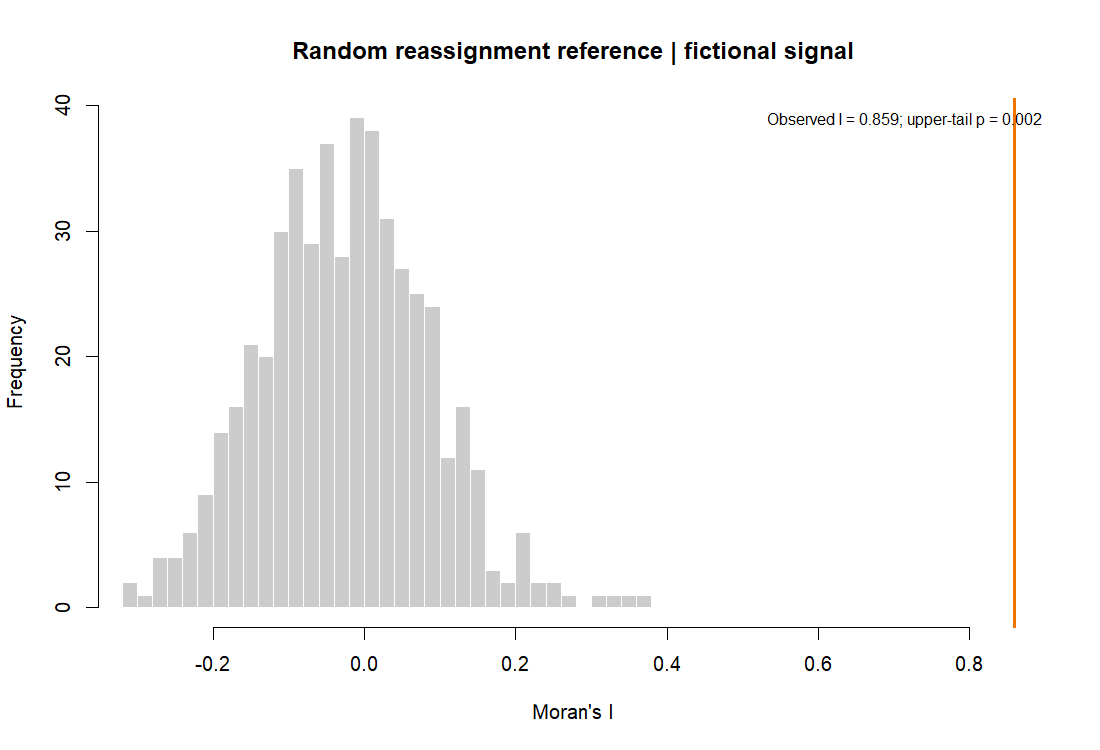

In [2]:
hist(null, breaks = 25, col = "grey80", border = "white", xlim = range(c(null, observed)),
     xlab = "Moran's I", main = "Random reassignment reference | fictional signal")
abline(v = observed, col = "darkorange2", lwd = 3)
legend("topright", sprintf("Observed I = %.3f; upper-tail p = %.3f", observed, p_greater), bty = "n", cex = .8)

In [ ]:
if (requireNamespace("spdep", quietly = TRUE)) {
  listw <- spdep::mat2listw(W, style = "W", zero.policy = FALSE)
  package_i <- spdep::moran(signal, listw, n = n, S0 = spdep::Szero(listw))$I
  stopifnot(abs(package_i - observed) < 1e-10)
  print(data.frame(our_I = observed, spdep_I = package_i))
} else message("Optional spdep comparison skipped: package not installed. Try webr::install('spdep').")

## Sensitivity is part of the analysis
Queen adjacency includes diagonal neighbors. Recalculate rather than describing the change
as cosmetic. The simulation's smooth gradient creates spatial association by construction.

In [3]:
queen <- pmax(outer(grid$x, grid$x, function(a,b) abs(a-b)),
              outer(grid$y, grid$y, function(a,b) abs(a-b))) == 1
Wq <- queen / rowSums(queen)
print(data.frame(weights = c("rook", "queen"), I = c(observed, moran_i(signal, Wq))))

  weights         I
1    rook 0.8589934
2   queen 0.8101583


## Practice and check
1. Replace the smooth field with independent noise; repeat across several seeds.
2. Increase B to 999. Explain why the smallest attainable p-value changes.
3. Remove every edge for one area. Decide how to handle the island before computing a statistic.
**Checkpoint:** the plus-one permutation correction prevents a zero p-value. This is an upper-tail
test for positive association, not a two-sided test. Local cluster maps would need additional
inference and multiple-comparison decisions. Aggregating areas can change results (MAUP).

## Sources
[spdep Moran implementation and formula](https://r-spatial.github.io/spdep/reference/moran.html);
[spdep permutation test](https://r-spatial.github.io/spdep/reference/moran.mc.html);
[Bivand and Wong (2018)](https://doi.org/10.1007/s11749-018-0599-x).